In [57]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS, summarize)
from ISLP import confusion_table
from sklearn.discriminant_analysis import \
    (LinearDiscriminantAnalysis as LDA,
        QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [19]:
Boston = load_data("Boston")

In [26]:
median_crime = Boston['crim'].median()
Boston['crim01'] = (Boston['crim'] > median_crime).astype(int)

In [27]:
Boston

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv,crim01
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0,0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6,0
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7,0
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4,0
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4,0
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6,0
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9,0
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0,0


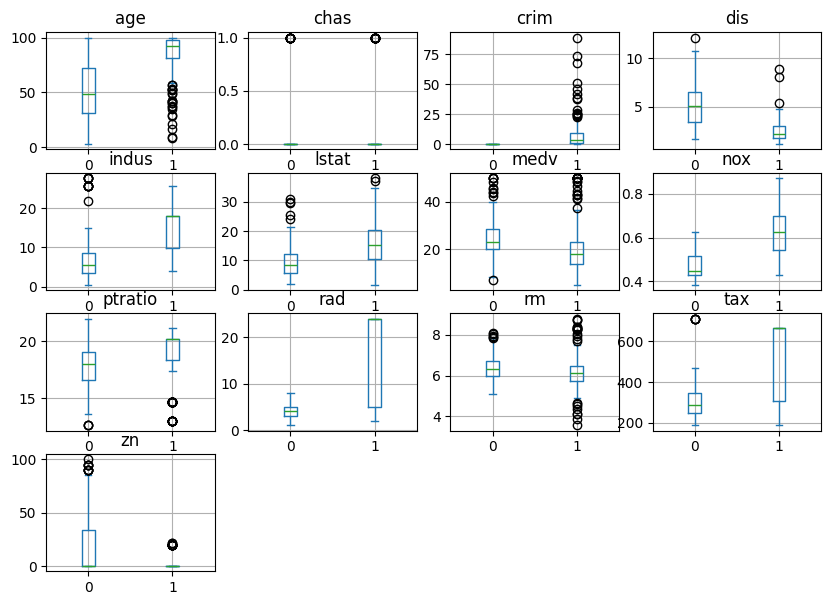

In [36]:
Boston.plot.box(by='crim01', layout=(4, 4), figsize=(10,7), grid=True);

In [37]:
Boston.corr()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv,crim01
crim,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305,0.409395
zn,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445,-0.436151
indus,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725,0.603260
chas,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260,0.070097
nox,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321,0.723235
rm,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360,-0.156372
age,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955,0.613940
dis,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929,-0.616342
rad,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626,0.619786
tax,0.582764,-0.314563,0.720760,-0.035587,0.668023,-0.292048,0.506456,-0.534432,0.910228,1.000000,0.460853,0.543993,-0.468536,0.608741


In [39]:
# I'll use age, indus, nox, tax, lstat, medv


In [62]:
def lda_model(data, predictors, target='crim01', test_size=0.3, random_state=1):
    X = data[predictors]
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    model = LDA()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, preds)
    return model, accuracy

In [48]:
def qda_model(data, predictors, target='crim01', test_size=0.3, random_state=1):
    X = data[predictors]
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    model = QDA()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, preds)
    return model, accuracy

In [42]:
def naive_bayes_model(data, predictors, target='crim01', test_size=0.3, random_state=1):
    X = data[predictors]
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    model = GaussianNB()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, preds)
    return model, accuracy

In [44]:
def knn_model(data, predictors, target='crim01', k=5, test_size=0.3, random_state=1):
    X = data[predictors]
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, preds)
    return model, accuracy

In [68]:
lda_acc = {}
qda_acc = {}
nb_acc = {}
knn_acc = {}

In [124]:
predictors_set = ["nox", "lstat", "rm"]
lda, acc_lda = lda_model(Boston, predictors_set)
lda_acc["nox lstat rm"] = acc_lda

In [125]:
lda_acc

{'age lstat': 0.7894736842105263,
 'lstat': 0.6907894736842105,
 'age': 0.7763157894736842,
 'medv': 0.618421052631579,
 'medv lstat': 0.6973684210526315,
 'nox': 0.8157894736842105,
 'tax': 0.7039473684210527,
 'indus': 0.743421052631579,
 'nox age': 0.8289473684210527,
 'nox age tax': 0.8355263157894737,
 'nox tax': 0.8421052631578947,
 'age tax': 0.7960526315789473,
 'nox indus': 0.7960526315789473,
 'nox lstat rm': 0.8092105263157895}

In [139]:
predictors_set = ["crim"]
qda, acc_qda = qda_model(Boston, predictors_set)
qda_acc["crim"] = acc_qda

In [140]:
qda_acc

{'nox tax': 0.8223684210526315,
 'nox age': 0.8092105263157895,
 'indus age': 0.7828947368421053,
 'age': 0.7631578947368421,
 'nox': 0.8092105263157895,
 'tax': 0.7105263157894737,
 'lstat': 0.6973684210526315,
 'nox lstat': 0.8421052631578947,
 'age lstat': 0.7960526315789473,
 'nox lstat dis': 0.8421052631578947,
 'nox lstat rm': 0.8552631578947368,
 'nox lstat rm dis': 0.8486842105263158,
 'crim': 0.9671052631578947}

In [141]:
predictors_set = ["zn", "indus"]
nb, acc_nb = naive_bayes_model(Boston, predictors_set)
nb_acc["zn indus"] = acc_nb

In [142]:
nb_acc

{'nox lstat rm dis': 0.8092105263157895,
 'nox lstat rm': 0.8289473684210527,
 'nox': 0.8092105263157895,
 'lstat rm ptratio': 0.7631578947368421,
 'age dis nox': 0.8157894736842105,
 'crim zn indus': 0.9605263157894737,
 'zn indus': 0.75}

In [161]:
predictors_set = ["age", "rm", "ptratio"]
knn, acc_knn = knn_model(Boston, predictors_set, k=4)
knn_acc["age rm ptratio 4"] = acc_knn

In [162]:
knn_acc

{'zn indus': 0.9539473684210527,
 'zn indus 4': 0.9539473684210527,
 'zn indus 3': 0.9539473684210527,
 'zn indus 9': 0.9539473684210527,
 'zn indus 50': 0.8157894736842105,
 'zn indus 1': 0.9539473684210527,
 'zn indus 14': 0.8618421052631579,
 'nox lstat rm 4': 0.7105263157894737,
 'nox lstat dis 4': 0.7960526315789473,
 'age rm ptratio 4': 0.743421052631579}

In [163]:
## Results: performing knn with k = 4 and using zn and indus as predictors yields a 95.4 accuracy. Could be fluke but idc at this point